# Predicting Airbnb Price Tiers from Photos, Text and Listing Details
**Project 2.2 — individual implementation (Multimodal Data Analysis)**

**Task.** Classify each Melbourne Airbnb listing as *budget*, *mid-range* or *premium* (nightly-price tertiles) from three modalities: the main **photo** (image), the host-written **title + description** (text) and the **listing details** (tabular).

**Pipeline.** data → privacy filter → grouped split → labels → quality assessment & preprocessing → frozen feature extraction (EfficientNet-B0 + BERT; comparison ViT-B/16 + Sentence-BERT; CLIP reference) → unimodal baselines → **early**, **late** and **attention-based intermediate fusion** → evaluation (diverse metrics, overfitting, efficiency, modality contribution, error analysis, fairness).

**How to run (Google Colab, T4 GPU).** Put this notebook and `airbnb_mm.py` in one Google Drive folder (default `MyDrive/airbnb-multimodal-price`), open the notebook in Colab, choose *Runtime → Change runtime type → T4 GPU* and *Run all*. All downloads, embeddings and results are cached in that folder, so a second run takes minutes. First run ≈ 1–1.5 h (the photo download dominates).

In [1]:
# ---- 0. Setup ------------------------------------------------------------------------------------
import os, sys, json, time, warnings
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/airbnb-multimodal-price"
    !pip -q install sentence-transformers
    !python -m spacy download en_core_web_sm -q
else:
    PROJECT_DIR = os.environ.get("PROJECT_DIR", os.getcwd())
sys.path.insert(0, PROJECT_DIR)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, log_loss
from sklearn.preprocessing import StandardScaler
import airbnb_mm as mm

warnings.filterwarnings("ignore", category=UserWarning)
from PIL import Image as _PILImage
warnings.filterwarnings("ignore", category=_PILImage.DecompressionBombWarning)
mm.set_seed(mm.SEED)
DEVICE = mm.get_device()
CACHE = os.path.join(PROJECT_DIR, "cache"); IMG_DIR = os.path.join(CACHE, "images")
FIG_DIR = os.path.join(PROJECT_DIR, "figures"); RES_DIR = os.path.join(PROJECT_DIR, "results")
for d in (CACHE, IMG_DIR, FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)
FAST = bool(int(os.environ.get("FAST", "0")))           # small grids, for smoke tests only
print("NOTEBOOK VERSION v3 (precise name masking, PCA ablation, attention grid with inputs/lr)")
assert hasattr(mm, "NOT_NAMES"), "old airbnb_mm.py loaded - replace the file in Drive and restart the session"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "", "| project dir:", PROJECT_DIR)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORS = {"Image only": "#8172B3", "Tabular only": "#55A868", "Text only": "#CCB974",
          "Early fusion": "#4C72B0", "Late fusion": "#DD8452", "Attention fusion": "#C44E52"}
RESULTS = {}
FIG_NO = [0]; TAB_NO = [0]

def finish_figure(fig, caption, name):
    FIG_NO[0] += 1
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f"fig{FIG_NO[0]:02d}_{name}.png"), dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Figure {FIG_NO[0]}. {caption}")

def show_table(table, caption, name, precision=3):
    TAB_NO[0] += 1
    table.to_csv(os.path.join(RES_DIR, f"table{TAB_NO[0]:02d}_{name}.csv"))
    print(f"Table {TAB_NO[0]}. {caption}")
    display(table.round(precision) if hasattr(table, "round") else table)

def save_results():
    json.dump(RESULTS, open(os.path.join(RES_DIR, "results.json"), "w"), indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))

Mounted at /content/drive
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
NOTEBOOK VERSION v3 (precise name masking, PCA ablation, attention grid with inputs/lr)
device: cuda Tesla T4 | project dir: /content/drive/MyDrive/airbnb-multimodal-price


## 1. Data and privacy filter
Inside Airbnb, Melbourne snapshot of 16 September 2026 (CC BY 4.0). Before any analysis, every `host_*` column, the listing URL and the exact **latitude/longitude** are removed (re-identification risk, Szanto & Mehta 2018; Week 7). Only the area name (`neighbourhood_cleansed`) is kept. `host_id` survives only as a salted hash used to keep a host's listings in the same split, and is discarded after splitting.

In [2]:
raw = mm.load_listings(CACHE)
df, privacy_info = mm.privacy_filter(raw)
df["price_num"] = mm.parse_price(df["price"])
n_raw = len(df)
no_price = df["price_num"].isna() | (df["price_num"] <= 0)
df = df[~no_price].reset_index(drop=True)
RESULTS["data"] = {"n_raw": n_raw, "n_columns_raw": privacy_info["n_raw_columns"],
                   "n_columns_dropped": privacy_info["n_dropped_columns"],
                   "n_host_columns_dropped": len(privacy_info["dropped_host_columns"]),
                   "share_no_price": float(no_price.mean()), "n_with_price": len(df)}
print(json.dumps(RESULTS["data"], indent=1))

{
 "n_raw": 25715,
 "n_columns_raw": 90,
 "n_columns_dropped": 74,
 "n_host_columns_dropped": 20,
 "share_no_price": 0.26097608399766675,
 "n_with_price": 19004
}


## 2. Leakage-safe grouped split and labels
**Groups.** 12.4% of descriptions are copied across listings (initial analysis) and multi-listing hosts reuse photos and wording. A union-find over *same host* and *same description* builds groups; `StratifiedGroupKFold` then assigns whole groups to a **70 / 15 / 15** train / validation / test split, stratified on price quintiles.

**Labels.** The 99th-percentile outlier cap and the tertile edges are estimated **on the training split only** and applied to all splits (change from the proposal, which used the full data).

Table 1. Grouped split. Cap (train 99th pct) = $1,658; tertile edges = $200 / $323.


,listings,groups,share budget,share mid-range,share premium
train,13702.0,5843.0,0.335,0.331,0.333
val,2701.0,1355.0,0.315,0.335,0.350
test,2430.0,1222.0,0.301,0.338,0.361


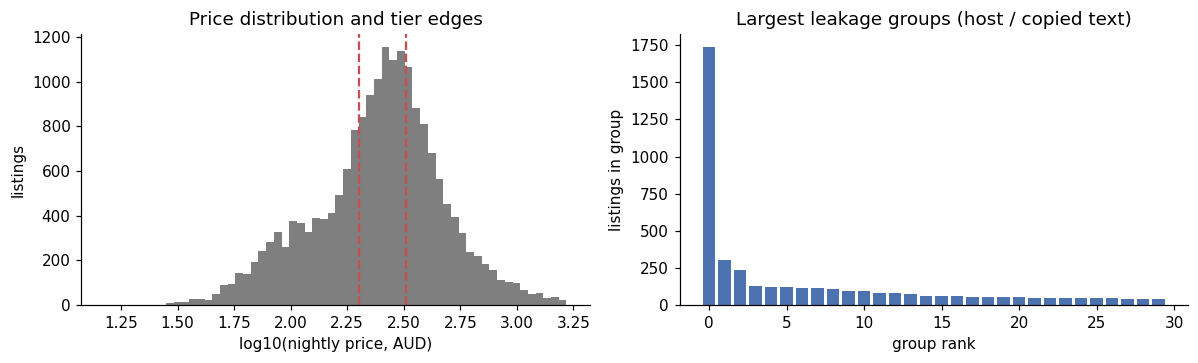

Figure 1. Left: nightly price (log scale) with the training-set tertile edges. Right: the 30 largest groups; multi-listing hosts would otherwise leak near-duplicate listings across splits.


In [3]:
groups = mm.build_groups(df)
strata = pd.qcut(np.log(df["price_num"]), 5, labels=False).values      # only to balance the split
split = mm.grouped_split(strata, groups)
y_all, kept, cap, edges = mm.make_labels(df["price_num"], split)
df, split, groups, y = df[kept].reset_index(drop=True), split[kept], groups[kept], y_all[kept]
df = df.drop(columns=["_host_key"])                                    # host hash no longer needed
IDX = {s: np.where(split == s)[0] for s in ["train", "val", "test"]}

split_tab = pd.DataFrame({s: [len(IDX[s]), len(np.unique(groups[IDX[s]]))] + list(np.bincount(y[IDX[s]], minlength=3) / len(IDX[s]))
                          for s in IDX}, index=["listings", "groups"] + [f"share {c}" for c in mm.CLASSES]).T
show_table(split_tab, f"Grouped split. Cap (train 99th pct) = ${cap:,.0f}; tertile edges = ${edges[0]:.0f} / ${edges[1]:.0f}.", "split")
gsize = pd.Series(groups).value_counts()
RESULTS["split"] = {"cap": cap, "edges": edges, "n_after_cap": len(df), "removed_by_cap": int((~kept).sum()),
                    "n_groups": int(gsize.size), "largest_group": int(gsize.iloc[0]),
                    "share_in_multi_listing_groups": float((gsize[gsize > 1].sum()) / len(df)),
                    **{f"n_{s}": len(IDX[s]) for s in IDX}}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(np.log10(df["price_num"]), bins=60, color="#7f7f7f")
for e in edges: ax[0].axvline(np.log10(e), color="#C44E52", ls="--")
ax[0].set(xlabel="log10(nightly price, AUD)", ylabel="listings", title="Price distribution and tier edges")
ax[1].bar(range(min(30, gsize.size)), gsize.values[:30], color="#4C72B0")
ax[1].set(xlabel="group rank", ylabel="listings in group", title="Largest leakage groups (host / copied text)")
finish_figure(fig, "Left: nightly price (log scale) with the training-set tertile edges. Right: the 30 largest groups; "
              "multi-listing hosts would otherwise leak near-duplicate listings across splits.", "price_groups")

## 3. Data quality assessment and preprocessing (Week 2)
### 3.1 Text: title + description

In [4]:
df["text"] = [mm.clean_text(n, d) for n, d in zip(df["name"], df["description"])]
name_cache = os.path.join(CACHE, "texts_name_masked_v3.csv")
if os.path.exists(name_cache) and len(pd.read_csv(name_cache)) == len(df):
    _nc = pd.read_csv(name_cache, keep_default_na=False); df["text"], name_share = _nc["text"].values, float(_nc["name_share"].iloc[0])
else:
    masked, name_share, name_info = mm.mask_person_names(df["text"].tolist())
    df["text"] = masked
    print("most frequently MASKED strings:", name_info["masked_top"])
    print("most frequent PERSON entities KEPT (frequent -> suburbs / landmarks / brands):", name_info["kept_top"])
    json.dump(name_info, open(os.path.join(RES_DIR, "name_masking.json"), "w"), indent=1)
    if name_share is not None:
        pd.DataFrame({"text": masked, "name_share": name_share}).to_csv(name_cache, index=False)
print("share of texts with a person name masked:", name_share)
words = df["text"].str.split().str.len()
pii = mm.pii_counts(df["description"])
dup_desc = df["description"].dropna().str.strip().str.lower().duplicated(keep=False).mean()
non_ascii = df["description"].fillna("").map(lambda s: sum(ord(c) > 127 and c.isalpha() for c in s) / max(len(s), 1) > 0.3).mean()
RESULTS["text_quality"] = {"missing_description": float(df["description"].isna().mean()),
                           "words_median": float(words.median()), "words_p95": float(words.quantile(.95)),
                           "short_under_10_words": float((words < 10).mean()), "share_in_duplicate_descriptions": float(dup_desc),
                           "mostly_non_latin_text": float(non_ascii), "texts_with_person_name_masked": name_share, **{f"pii_{k}": v for k, v in pii.items()}}
print(json.dumps(RESULTS["text_quality"], indent=1))

most frequently MASKED strings: {'Kew': 42, 'Sandringham': 42, 'Spencer': 37, 'Cosy': 37, 'Box Hill': 35, 'Laundry': 34, 'Collins St': 33, 'Dandenongs': 33, 'Glen Iris': 33, 'Parks': 33, 'Merri Creek': 33, 'Enjoy Melbourne': 33, 'Southbank': 32, 'Yarraville': 32, 'Mel': 31, 'Asian Grocery': 31, 'Fitzroy St': 30, 'Balaclava': 30, 'Bourke St Mall': 29, 'Brunswick St': 29, 'Lonsdale St': 28, 'Sydney Road': 27, 'Eureka Tower': 27, 'Central St Kilda': 26, 'Smeg': 26}
most frequent PERSON entities KEPT (frequent -> suburbs / landmarks / brands): {'St Kilda': 825, 'WiFi': 499, 'Albert Park': 322, 'Fitzroy': 305, 'Albert Park Lake': 218, 'St Kilda Beach': 178, 'Escape': 177, 'Rod Laver Arena': 140, 'Kick': 138, 'Art Deco': 138, 'Sleeps': 136, 'Glen Waverley': 133, 'Coles': 131, 'Balcony': 129, 'Southbank Promenade': 122, 'Wifi': 115, 'Miele': 114, 'Melbourne': 112, 'Tram': 110, 'Spencer St': 100, 'St Kilda Road': 99, 'Cozy': 97, 'Footscray': 96, 'Fitzroy North': 95, 'bush': 84}
share of texts 

### 3.2 Tabular: missing values and outliers

In [5]:
base = mm.TabularEncoder.base_frame(df)
tq = pd.DataFrame({"missing share": base[mm.TabularEncoder.NUMERIC].isna().mean(),
                   "median": base[mm.TabularEncoder.NUMERIC].median(),
                   "99th pct": base[mm.TabularEncoder.NUMERIC].quantile(.99),
                   "max": base[mm.TabularEncoder.NUMERIC].max()})
show_table(tq, "Tabular quality on the cleaned data. Missing values are imputed with training medians plus missing-value "
           "flags; review_scores_rating is missing for listings without reviews and gets a 'no_reviews_yet' flag.", "tabular_quality")

tab_enc = mm.TabularEncoder(include_area=True).fit(df.iloc[IDX["train"]])
tab_enc_noarea = mm.TabularEncoder(include_area=False).fit(df.iloc[IDX["train"]])
TAB = tab_enc.transform(df); TAB_NOAREA = tab_enc_noarea.transform(df)
print(f"tabular features: {TAB.shape[1]} with area, {TAB_NOAREA.shape[1]} without area "
      f"({len(tab_enc.amenities_)} amenity indicators, {len(tab_enc.areas_)} areas)")

Table 2. Tabular quality on the cleaned data. Missing values are imputed with training medians plus missing-value flags; review_scores_rating is missing for listings without reviews and gets a 'no_reviews_yet' flag.


,missing share,median,99th pct,max
accommodates,0.000,4.000,12.000,16.000
bedrooms,0.001,2.000,5.000,16.000
beds,0.010,2.000,8.000,26.000
bathrooms,0.001,1.000,4.000,15.000
n_amenities,0.000,40.000,72.000,91.000
log_reviews,0.000,2.773,6.020,8.093
review_scores_rating,0.148,4.860,5.000,5.000
log_min_nights,0.001,1.099,3.434,5.903


tabular features: 104 with area, 74 without area (40 amenity indicators, 30 areas)


### 3.3 Images: download, quality and privacy screen
Photos are downloaded once at 480 px (EXIF orientation corrected). Week 2 indicators are computed for every photo; a pretrained person detector flags photos showing people, which are treated as a **missing image** (privacy commitment in the proposal) rather than discarding the listing.

{
 "download_seconds_this_run": 18.95562582399998,
 "readable": 0.975521690649392,
 "person_flagged": 0.005469123347315882,
 "image_present": 0.9700525673020761,
 "median_width": 480.0,
 "median_height": 321.0,
 "very_dark_share": 0.0019646365422396855,
 "blur_threshold_p5": 452.5539916992188,
 "portrait_share": 0.1594541496309669
}


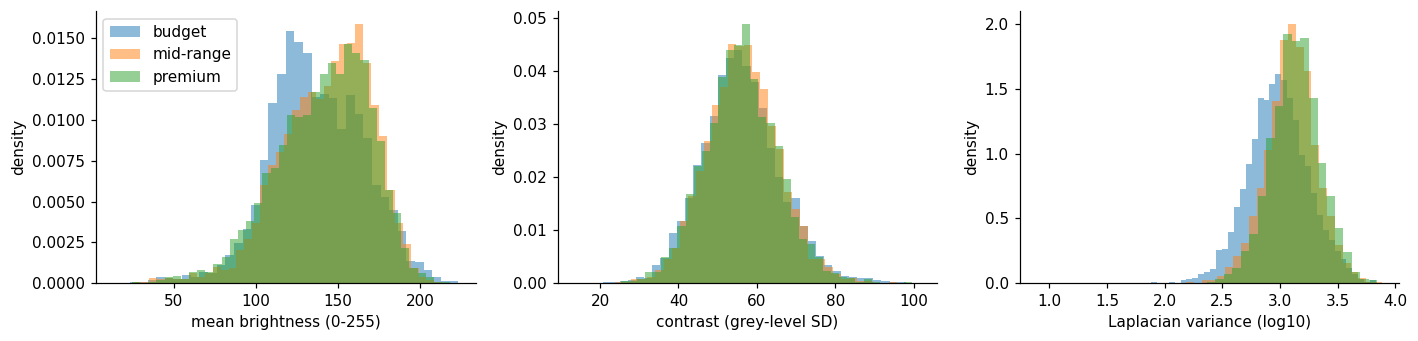

Figure 2. Week 2 image-quality indicators by price tier. Premium photos are slightly brighter and sharper, i.e. photo quality itself carries price signal (professional photography), which is a possible bias.


In [6]:
with mm.Timer() as t_dl:
    downloaded = mm.download_images(df, IMG_DIR)
PATHS = [mm.image_path(IMG_DIR, i) for i in df["id"]]
iq_path = os.path.join(CACHE, "image_quality.csv")
if os.path.exists(iq_path) and len(pd.read_csv(iq_path)) == len(df):
    iq = pd.read_csv(iq_path)
else:
    iq = mm.image_quality(PATHS); iq.to_csv(iq_path, index=False)
person, _ = mm.cached_array(os.path.join(CACHE, "person_flags.npy"),
                            lambda: mm.detect_people([p if ok else "" for p, ok in zip(PATHS, iq["readable"])]).astype(np.uint8))
person = person.astype(bool)
blur_thr = iq["laplacian_var"].quantile(0.05)
IMAGE_PRESENT = iq["readable"].values.astype(bool) & ~person
RESULTS["image_quality"] = {"download_seconds_this_run": t_dl.seconds, "readable": float(iq["readable"].mean()),
                            "person_flagged": float(person.mean()), "image_present": float(IMAGE_PRESENT.mean()),
                            "median_width": float(iq["width"].median()), "median_height": float(iq["height"].median()),
                            "very_dark_share": float((iq["brightness"] < 40).mean()), "blur_threshold_p5": float(blur_thr),
                            "portrait_share": float((iq["aspect"] < 1).mean())}
print(json.dumps(RESULTS["image_quality"], indent=1))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, col, lab in zip(ax, ["brightness", "contrast", "laplacian_var"], ["mean brightness (0-255)", "contrast (grey-level SD)", "Laplacian variance (log10)"]):
    v = iq[col].dropna(); v = np.log10(v + 1) if col == "laplacian_var" else v
    for k, c in enumerate(mm.CLASSES):
        a.hist(v[y[iq[col].notna().values] == k], bins=40, alpha=.5, density=True, label=c)
    a.set(xlabel=lab, ylabel="density")
ax[0].legend()
finish_figure(fig, "Week 2 image-quality indicators by price tier. Premium photos are slightly brighter and sharper, i.e. "
              "photo quality itself carries price signal (professional photography), which is a possible bias.", "image_quality")

### 3.4 Preprocessing summary
| Modality | Steps (fitted on training data only where statistics are needed) |
|---|---|
| Image | EXIF transpose → 480 px JPEG → backbone transform (resize 256, centre crop 224, ImageNet normalisation) · unreadable / person photos → missing-modality mask |
| Text | title + description · HTML unescape and tag removal · e-mail / URL / phone masking · BERT WordPiece, max 256 tokens |
| Tabular | numeric parsing (bathrooms text → number, shared flag) · log1p of skewed counts · median imputation + missing flags · one-hot room / property type / area · top-40 amenity indicators · standardisation |

## 4. Feature extraction (Week 3) and feature quality
Frozen pretrained encoders, cached once. **Main set** (proposal): EfficientNet-B0 (CNN, 1,280-d) + BERT-base mean pooling (768-d). **Comparison set**: ViT-B/16 (transformer, 768-d) + Sentence-BERT `all-mpnet-base-v2` (768-d). **Reference**: CLIP ViT-B/32 image and text encoders (512-d each), a contrastive vision–language model (Week 3/8) used for comparison only.

In [7]:
texts = df["text"].tolist()
ENC = {}
def emb(name, fn):
    arr, meta = mm.cached_array(os.path.join(CACHE, f"emb_{name}.npy"), fn, os.path.join(CACHE, f"emb_{name}.json"))
    assert len(arr) == len(df), f"cached {name} has {len(arr)} rows, data has {len(df)} - delete the cache file"
    ENC[name] = meta
    return arr

FEATS = {
    "EffNet-B0 + BERT": {"image": emb("effnet_b0", lambda: mm.extract_image_features(PATHS, "efficientnet_b0")),
                          "text": emb("bert_mean_v3", lambda: mm.extract_bert_mean(texts))},
    "ViT-B/16 + SBERT": {"image": emb("vit_b_16", lambda: mm.extract_image_features(PATHS, "vit_b_16")),
                          "text": emb("sbert_mpnet_v3", lambda: mm.extract_sbert(texts))},
    "CLIP ViT-B/32":    {"image": emb("clip_image", lambda: mm.extract_clip_image_features(PATHS)),
                          "text": emb("clip_text_v3", lambda: mm.extract_clip_text(texts))},
}
MAIN = "EffNet-B0 + BERT"
enc_tab = pd.DataFrame({k: {"dim": FEATS[s][m].shape[1], "seconds (cached run)": ENC[k].get("seconds", np.nan),
                            "note": ENC[k].get("truncated_share", "")}
                        for s, k, m in [(MAIN, "effnet_b0", "image"), (MAIN, "bert_mean_v3", "text"),
                                        ("ViT-B/16 + SBERT", "vit_b_16", "image"), ("ViT-B/16 + SBERT", "sbert_mpnet_v3", "text"),
                                        ("CLIP ViT-B/32", "clip_image", "image"), ("CLIP ViT-B/32", "clip_text_v3", "text")]}).T
show_table(enc_tab, "Encoders: embedding size and extraction time on the full data (T4 GPU). 'note' = share of texts "
           "truncated at BERT's 256-token limit.", "encoders")
RESULTS["encoders"] = enc_tab.to_dict("index")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (24 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Table 3. Encoders: embedding size and extraction time on the full data (T4 GPU). 'note' = share of texts truncated at BERT's 256-token limit.


,dim,seconds (cached run),note
effnet_b0,1280,137.422342,
bert_mean_v3,768.0,64.963175,0.000425
vit_b_16,768,137.424734,
sbert_mpnet_v3,768,157.325244,
clip_image,512,176.677465,
clip_text_v3,512,58.336176,


**Feature quality.** A linear probe (multinomial logistic regression, train → validation) measures how much price signal each embedding carries before any fusion (Week 3 / Assignment 2 Task 2).

In [8]:
def probe(X, C=0.5):
    sc = StandardScaler().fit(X[IDX["train"]])
    clf = LogisticRegression(C=C, max_iter=3000).fit(sc.transform(X[IDX["train"]]), y[IDX["train"]])
    P = clf.predict_proba(sc.transform(X[IDX["val"]]))
    return {"val_accuracy": accuracy_score(y[IDX["val"]], P.argmax(1)),
            "val_macro_f1": f1_score(y[IDX["val"]], P.argmax(1), average="macro")}

probe_rows = {f"{s} | {m}": probe(np.where(IMAGE_PRESENT[:, None] | (m != "image"), FEATS[s][m], 0))
              for s in FEATS for m in ["image", "text"]}
probe_rows["Tabular (with area)"] = probe(TAB); probe_rows["Tabular (without area)"] = probe(TAB_NOAREA)
from sklearn.feature_extraction.text import TfidfVectorizer
tfv = TfidfVectorizer(min_df=5, max_features=20000, ngram_range=(1, 2)).fit(df["text"].iloc[IDX["train"]])
Xtf = tfv.transform(df["text"])
clf_tf = LogisticRegression(C=2.0, max_iter=3000).fit(Xtf[IDX["train"]], y[IDX["train"]])
p_tf = clf_tf.predict(Xtf[IDX["val"]])
probe_rows["Text | TF-IDF (Week 2 baseline)"] = {"val_accuracy": accuracy_score(y[IDX["val"]], p_tf),
                                                 "val_macro_f1": f1_score(y[IDX["val"]], p_tf, average="macro")}
probe_tab = pd.DataFrame(probe_rows).T.sort_values("val_macro_f1", ascending=False)
show_table(probe_tab, "Linear-probe quality of every feature set (logistic regression, validation split; chance = 0.333).", "linear_probe")
RESULTS["linear_probe"] = probe_tab.to_dict("index")

Table 4. Linear-probe quality of every feature set (logistic regression, validation split; chance = 0.333).


,val_accuracy,val_macro_f1
Tabular (with area),0.680,0.685
Tabular (without area),0.672,0.677
Text | TF-IDF (Week 2 baseline),0.598,0.603
CLIP ViT-B/32 | text,0.595,0.599
ViT-B/16 + SBERT | text,0.573,0.578
EffNet-B0 + BERT | text,0.558,0.560
CLIP ViT-B/32 | image,0.529,0.532
ViT-B/16 + SBERT | image,0.499,0.502
EffNet-B0 + BERT | image,0.458,0.461


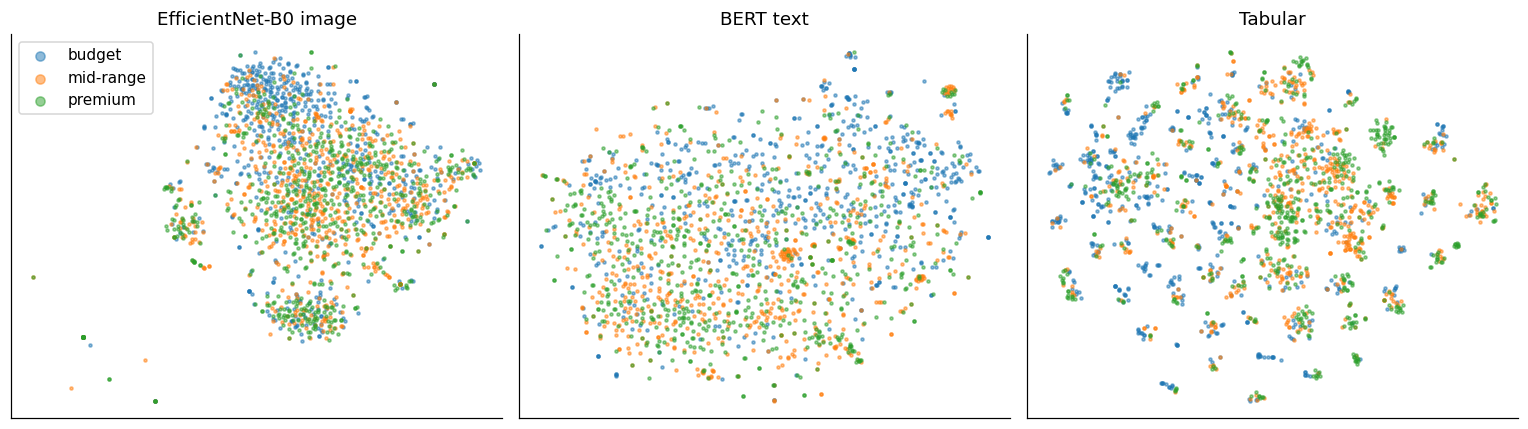

Figure 3. t-SNE of validation embeddings (Week 3). Tabular features separate the tiers best; image and text show gradients rather than clusters, i.e. weaker but complementary signal.


In [9]:
from sklearn.manifold import TSNE
sub = np.random.default_rng(0).choice(IDX["val"], size=min(2000, len(IDX["val"])), replace=False)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (lab, X) in zip(ax, [("EfficientNet-B0 image", FEATS[MAIN]["image"]), ("BERT text", FEATS[MAIN]["text"]), ("Tabular", TAB)]):
    Z = TSNE(2, init="pca", random_state=0, perplexity=30).fit_transform(StandardScaler().fit_transform(X[sub]))
    for k, c in enumerate(mm.CLASSES):
        a.scatter(*Z[y[sub] == k].T, s=4, alpha=.5, label=c)
    a.set(title=lab, xticks=[], yticks=[])
ax[0].legend(markerscale=3)
finish_figure(fig, "t-SNE of validation embeddings (Week 3). Tabular features separate the tiers best; image and text show "
              "gradients rather than clusters, i.e. weaker but complementary signal.", "tsne")

## 5. Experimental set-up
* **Blocks.** For tree models the 1,280/768-d embeddings are reduced by PCA (128 components, fitted on training rows) so they do not swamp the ~100 tabular columns (Week 4: single-modality domination); the neural model uses standardised full embeddings.
* **Missing image** (unreadable or person photo): NaN for XGBoost, a uniform 'neutral' expert for late fusion, a masked token for attention fusion.
* **Selection protocol.** Hyperparameters by 5-fold group-stratified CV on training (XGBoost) or by validation loss (neural); late-fusion weights on validation; the **test split is used once**, in Section 7.

In [10]:
def make_blocks(enc_set=MAIN, tab=TAB, n_pca=128):
    tr = IDX["train"]
    img = FEATS[enc_set]["image"].copy(); img[~IMAGE_PRESENT] = 0
    out = {"pca": {}, "pcas": {}, "full": {}, "pca_var": {}}
    for m, X in [("image", img), ("text", FEATS[enc_set]["text"])]:
        fit_rows = tr[IMAGE_PRESENT[tr]] if m == "image" else tr
        f, var = mm.fit_pca(X[fit_rows], n_pca)
        out["pca"][m], out["pca_var"][m] = f(X), var
        out["pcas"][m] = StandardScaler().fit(out["pca"][m][fit_rows]).transform(out["pca"][m]).astype(np.float32)
        sc = StandardScaler().fit(X[fit_rows]); out["full"][m] = sc.transform(X).astype(np.float32)
    out["pca"]["tabular"] = out["pcas"]["tabular"] = out["full"]["tabular"] = tab
    return out

def sel(blocks, s):
    return {m: blocks[m][IDX[s]] for m in mm.MODALITIES}

BLOCKS = make_blocks()
PRESENT = np.stack([IMAGE_PRESENT, np.ones(len(df), bool), np.ones(len(df), bool)], 1)
RESULTS["pca_explained_variance"] = BLOCKS["pca_var"]
print("PCA(128) explained variance:", {k: round(v, 3) for k, v in BLOCKS["pca_var"].items()})
GRID = {"max_depth": [4, 6], "learning_rate": [0.1], "colsample_bytree": [0.5]} if FAST else \
       {"max_depth": [4, 6], "learning_rate": [0.05, 0.1], "colsample_bytree": [0.5, 0.8]}
XGB_KEYS = ["max_depth", "learning_rate", "colsample_bytree"]
VAL_P, TEST_P, TRAIN_P, MODELS, COST = {}, {}, {}, {}, {}

PCA(128) explained variance: {'image': 0.617, 'text': 0.88}


## 6. Solutions
### 6.1 Unimodal baselines (tuned XGBoost per modality)

In [11]:
SEARCH = {}
for m, name in [("image", "Image only"), ("tabular", "Tabular only"), ("text", "Text only")]:
    X = {s: BLOCKS["pca"][m][IDX[s]].copy() for s in IDX}
    if m == "image":
        for s in IDX: X[s][~IMAGE_PRESENT[IDX[s]]] = np.nan
    with mm.Timer() as t:
        SEARCH[name] = mm.tune_xgb_cv(X["train"], y[IDX["train"]], groups[IDX["train"]], GRID, DEVICE)
    params = mm.best_params(SEARCH[name], XGB_KEYS)
    clf = mm.make_xgb(params, DEVICE)
    with mm.Timer() as tf:
        clf.fit(X["train"], y[IDX["train"]])
    MODELS[name] = clf
    for s, store in [("train", TRAIN_P), ("val", VAL_P), ("test", TEST_P)]:
        store[name] = clf.predict_proba(X[s])
    COST[name] = {"tuning_s": t.seconds, "fit_s": tf.seconds, "params": params,
                  "size_kb": len(clf.get_booster().save_raw("ubj")) / 1024,
                  "infer_ms_per_1000": mm.inference_ms_per_1000(lambda: clf.predict_proba(X["test"]), len(X["test"]))}
    print(f"{name:13s} {params} | val macro-F1 {f1_score(y[IDX['val']], VAL_P[name].argmax(1), average='macro'):.3f}")

Image only    {'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.5, 'n_estimators': 341} | val macro-F1 0.504
Tabular only  {'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.5, 'n_estimators': 345} | val macro-F1 0.706
Text only     {'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8, 'n_estimators': 334} | val macro-F1 0.560


### 6.2 Solution 1 — Early fusion (feature-level, XGBoost)

In [12]:
EB = {s: sel(BLOCKS["pca"], s) for s in IDX}
Xe_train = mm.EarlyFusionXGB.concat(EB["train"], IMAGE_PRESENT[IDX["train"]])
with mm.Timer() as t:
    SEARCH["Early fusion"] = mm.tune_xgb_cv(Xe_train, y[IDX["train"]], groups[IDX["train"]], GRID, DEVICE)
early_params = mm.best_params(SEARCH["Early fusion"], XGB_KEYS)

# Ablation (Week 4, curse of dimensionality / single-modality domination): how many PCA components of the image
# and text embeddings should enter the concatenated vector? Chosen on validation log loss with the tuned params.
pca_rows, PCA_BLOCKS = [], {}
for k in ([16, 128] if FAST else [8, 16, 32, 64, 128]):
    PCA_BLOCKS[k] = BLOCKS if k == 128 else make_blocks(MAIN, TAB, k)
    Ek = {s: sel(PCA_BLOCKS[k]["pca"], s) for s in ["train", "val"]}
    ek = mm.EarlyFusionXGB(early_params, DEVICE).fit(Ek["train"], y[IDX["train"]], IMAGE_PRESENT[IDX["train"]])
    Pk = ek.predict_proba(Ek["val"], IMAGE_PRESENT[IDX["val"]])
    pca_rows.append({"pca_components": k, "n_features": sum(Ek["train"][m].shape[1] for m in mm.MODALITIES),
                     "val_log_loss": log_loss(y[IDX["val"]], Pk), "val_macro_f1": f1_score(y[IDX["val"]], Pk.argmax(1), average="macro"),
                     **{f"gain_{m}": v for m, v in ek.modality_gain_share().items()}})
pca_tab = pd.DataFrame(pca_rows).set_index("pca_components")
N_PCA_EARLY = int(pca_tab["val_log_loss"].idxmin())
show_table(pca_tab, f"Early fusion: number of PCA components per embedding (validation). Selected: {N_PCA_EARLY}.", "early_pca_ablation", 4)
RESULTS["early_pca_ablation"] = {"selected": N_PCA_EARLY, "table": pca_tab.to_dict("index")}
EB = {s: sel(PCA_BLOCKS[N_PCA_EARLY]["pca"], s) for s in IDX}
early = mm.EarlyFusionXGB(early_params, DEVICE).fit(EB["train"], y[IDX["train"]], IMAGE_PRESENT[IDX["train"]])
MODELS["Early fusion"] = early
for s, store in [("train", TRAIN_P), ("val", VAL_P), ("test", TEST_P)]:
    store["Early fusion"] = early.predict_proba(EB[s], IMAGE_PRESENT[IDX[s]])
COST["Early fusion"] = {"tuning_s": t.seconds, "fit_s": early.fit_time_, "params": early_params,
                        "size_kb": len(early.model.get_booster().save_raw("ubj")) / 1024,
                        "infer_ms_per_1000": mm.inference_ms_per_1000(lambda: early.predict_proba(EB["test"], IMAGE_PRESENT[IDX["test"]]), len(IDX["test"]))}
gain_share = early.modality_gain_share()
RESULTS["early_gain_share"] = gain_share
show_table(SEARCH["Early fusion"].drop(columns=["curve_test", "curve_train"]),
           f"Early-fusion grid (5-fold group-stratified CV on training; {t.seconds:.0f}s). Gain share by modality: "
           + ", ".join(f"{k} {v:.0%}" for k, v in gain_share.items()), "early_grid", 4)

Table 5. Early fusion: number of PCA components per embedding (validation). Selected: 8.


,n_features,val_log_loss,val_macro_f1,gain_image,gain_tabular,gain_text
pca_components,,,,,,
8,120,0.6671,0.6961,0.0977,0.7868,0.1155
16,136,0.6701,0.7005,0.1216,0.7287,0.1496
32,168,0.6706,0.6997,0.1460,0.6742,0.1798
64,232,0.6753,0.6948,0.1644,0.6316,0.2040
128,360,0.6791,0.6998,0.1783,0.5951,0.2266


Table 6. Early-fusion grid (5-fold group-stratified CV on training; 141s). Gain share by modality: image 10%, tabular 79%, text 12%


,max_depth,learning_rate,colsample_bytree,n_estimators,cv_log_loss,cv_log_loss_sd,cv_train_log_loss
0,4,0.05,0.5,414,0.6612,0.0261,0.3647
1,4,0.05,0.8,420,0.6634,0.0234,0.3492
2,4,0.10,0.5,217,0.6658,0.0251,0.3567
3,6,0.05,0.5,234,0.6663,0.0257,0.2450
4,4,0.10,0.8,214,0.6669,0.0284,0.3467
5,6,0.05,0.8,228,0.6672,0.0261,0.2346
6,6,0.10,0.5,97,0.6704,0.0261,0.2907
7,6,0.10,0.8,102,0.6722,0.0269,0.2614


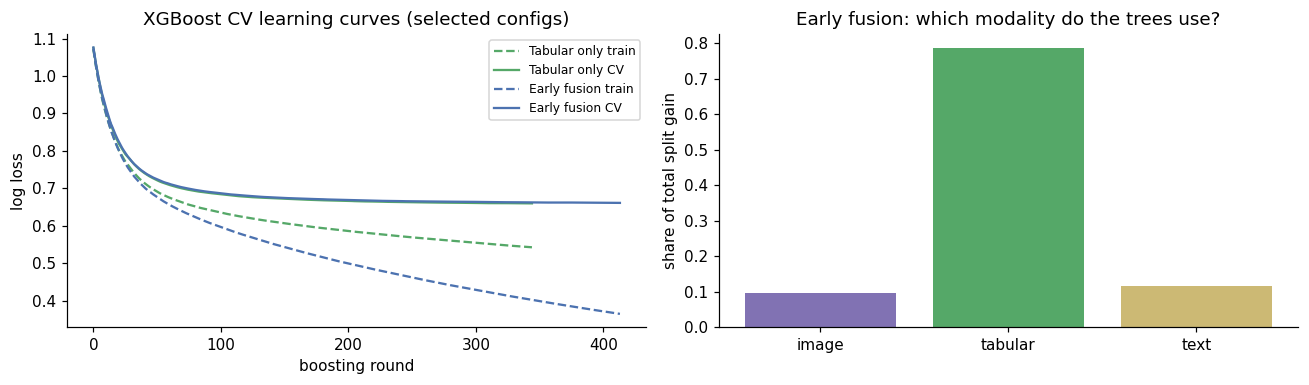

Figure 4. Left: training vs cross-validated log loss; the gap measures overfitting and early stopping fixes the number of trees. Right: modality share of the early-fusion model's split gain.


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name in ["Tabular only", "Early fusion"]:
    r = SEARCH[name].iloc[0]
    ax[0].plot(r["curve_train"], ls="--", color=COLORS[name], label=f"{name} train")
    ax[0].plot(r["curve_test"], color=COLORS[name], label=f"{name} CV")
ax[0].set(xlabel="boosting round", ylabel="log loss", title="XGBoost CV learning curves (selected configs)"); ax[0].legend(fontsize=8)
ax[1].bar(list(gain_share), list(gain_share.values()), color=[COLORS["Image only"], COLORS["Tabular only"], COLORS["Text only"]])
ax[1].set(ylabel="share of total split gain", title="Early fusion: which modality do the trees use?")
finish_figure(fig, "Left: training vs cross-validated log loss; the gap measures overfitting and early stopping fixes the "
              "number of trees. Right: modality share of the early-fusion model's split gain.", "early_curves_gain")

### 6.3 Solution 2 — Late fusion (decision-level; sum vs product rule)

In [14]:
P_val_list = [mm.neutral_image_proba(VAL_P["Image only"], IMAGE_PRESENT[IDX["val"]]), VAL_P["Tabular only"], VAL_P["Text only"]]
late = mm.LateFusion().fit(P_val_list, y[IDX["val"]])
def late_proba(store, s):
    return late.predict_proba([mm.neutral_image_proba(store["Image only"], IMAGE_PRESENT[IDX[s]]), store["Tabular only"], store["Text only"]])
for s, store in [("train", TRAIN_P), ("val", VAL_P), ("test", TEST_P)]:
    store["Late fusion"] = late_proba(store, s)
lw = pd.DataFrame({r: {**dict(zip(mm.MODALITIES, v["weights"])), "val_log_loss": v["val_log_loss"]} for r, v in late.search_.items()}).T
show_table(lw, f"Late-fusion weights learned on validation; selected rule: {late.rule}.", "late_weights", 4)
COST["Late fusion"] = {"fit_s": sum(COST[m]["fit_s"] for m in ["Image only", "Tabular only", "Text only"]),
                       "tuning_s": sum(COST[m]["tuning_s"] for m in ["Image only", "Tabular only", "Text only"]),
                       "size_kb": sum(COST[m]["size_kb"] for m in ["Image only", "Tabular only", "Text only"]),
                       "infer_ms_per_1000": sum(COST[m]["infer_ms_per_1000"] for m in ["Image only", "Tabular only", "Text only"])}
RESULTS["late_fusion"] = {"rule": late.rule, "weights": dict(zip(mm.MODALITIES, late.weights_)),
                          "search": {r: {"weights": list(v["weights"]), "val_log_loss": v["val_log_loss"]} for r, v in late.search_.items()}}

Table 7. Late-fusion weights learned on validation; selected rule: product.


,image,tabular,text,val_log_loss
sum,0.0000,0.9749,0.0251,0.6661
product,0.2437,0.9483,0.1516,0.6607


### 6.4 Solution 3 — Attention-based intermediate fusion (neural)
Modality encoders → modality tokens → multi-head attention block → attention pooling → classifier, with missing-modality masks and modality dropout. Grid on validation loss, then the best configuration is retrained with 3 seeds (Week 7: seed variance).

Table 8. Attention-fusion configurations (fixed {'hidden_dim': 128, 'dropout': 0.3, 'weight_decay': 0.01}; selection by validation log loss).


,inputs,lr,modality_dropout,best_epoch,val_log_loss,val_macro_f1,params,train_s
0,pca,0.0003,0.3,8,0.6853,0.6970,304132,11.3114
1,full,0.0010,0.3,1,0.6856,0.6983,533508,8.6098
2,pca,0.0010,0.3,1,0.6866,0.6922,304132,8.5161
3,full,0.0003,0.3,4,0.6952,0.6859,533508,9.7722
4,full,0.0010,0.0,0,0.6992,0.6893,533508,8.2728
5,pca,0.0010,0.0,1,0.7020,0.6929,304132,8.2516
6,pca,0.0003,0.0,1,0.7026,0.6877,304132,8.2153
7,full,0.0003,0.0,1,0.7061,0.6809,533508,8.2222


Table 9. Seed variability of the selected attention configuration {'inputs': 'pca', 'lr': 0.0003, 'modality_dropout': 0.3}.


,best_epoch,val_macro_f1,val_log_loss
seed,,,
0,4,0.6950,0.6806
1,7,0.6835,0.6855
2,8,0.6982,0.6830


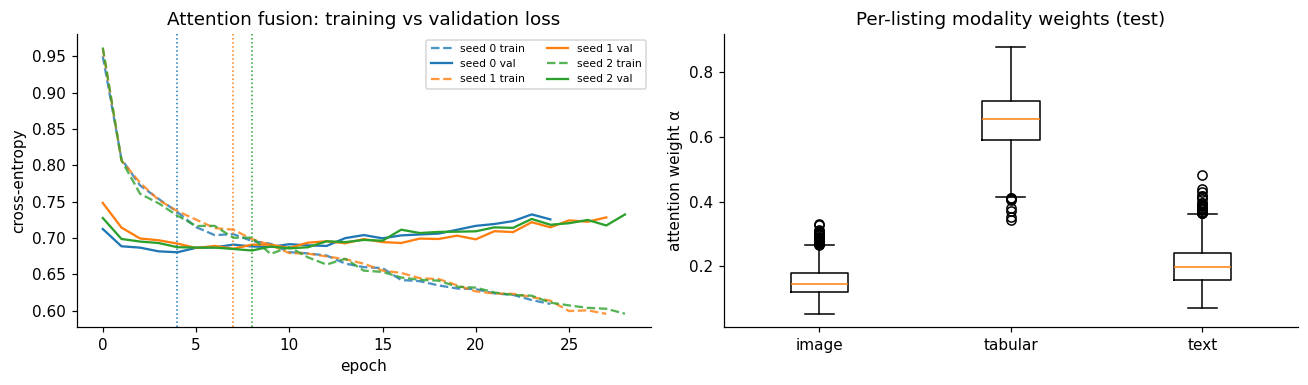

Figure 5. Left: learning curves for three seeds; dotted lines mark the early-stopping epoch (overfitting begins where validation loss turns up). Right: distribution of the learned modality weights.


In [15]:
# Inputs: standardised full embeddings (1,280 / 768-d) or standardised PCA-128 embeddings (fewer parameters, less
# overfitting). Learning rate and modality dropout (which may also hide the dominant tabular token) are tuned too.
FBS = {inp: {s: sel(BLOCKS["full" if inp == "full" else "pcas"], s) for s in IDX} for inp in ["full", "pca"]}
FIXED = dict(hidden_dim=64 if FAST else 128, dropout=0.3, weight_decay=1e-2)
ATT_GRID = [dict(inputs=i, lr=lr, modality_dropout=md) for i in (["pca"] if FAST else ["full", "pca"])
            for lr in ([1e-3] if FAST else [1e-3, 3e-4]) for md in ([0.3] if FAST else [0.0, 0.3])]
def att_fit(cfg, seed=mm.SEED, blocks=None):
    fb = blocks or FBS[cfg["inputs"]]
    dims = {m: fb["train"][m].shape[1] for m in mm.MODALITIES}
    return mm.train_attention((fb["train"], PRESENT[IDX["train"]], y[IDX["train"]]), (fb["val"], PRESENT[IDX["val"]], y[IDX["val"]]),
                              dims, **FIXED, lr=cfg["lr"], modality_dropout=cfg["modality_dropout"], seed=seed,
                              max_epochs=5 if FAST else 200)
att_rows = []
for cfg in ATT_GRID:
    mdl = att_fit(cfg)
    Pv, _ = mm.attention_predict(mdl, FBS[cfg["inputs"]]["val"], PRESENT[IDX["val"]])
    att_rows.append({**cfg, "best_epoch": mdl.best_epoch_, "val_log_loss": log_loss(y[IDX["val"]], Pv),
                     "val_macro_f1": f1_score(y[IDX["val"]], Pv.argmax(1), average="macro"),
                     "params": mdl.n_params_, "train_s": mdl.train_time_})
att_search = pd.DataFrame(att_rows).sort_values("val_log_loss").reset_index(drop=True)
show_table(att_search, f"Attention-fusion configurations (fixed {FIXED}; selection by validation log loss).", "attention_grid", 4)
best_cfg = {"inputs": att_search.iloc[0]["inputs"], "lr": float(att_search.iloc[0]["lr"]),
            "modality_dropout": float(att_search.iloc[0]["modality_dropout"])}
FB = FBS[best_cfg["inputs"]]

seed_models, seed_rows = [], []
for sd in [0, 1, 2]:
    mdl = att_fit(best_cfg, seed=sd)
    Pv, _ = mm.attention_predict(mdl, FB["val"], PRESENT[IDX["val"]])
    seed_models.append(mdl)
    seed_rows.append({"seed": sd, "best_epoch": mdl.best_epoch_, "val_macro_f1": f1_score(y[IDX["val"]], Pv.argmax(1), average="macro"),
                      "val_log_loss": log_loss(y[IDX["val"]], Pv)})
seed_tab = pd.DataFrame(seed_rows).set_index("seed")
show_table(seed_tab, f"Seed variability of the selected attention configuration {best_cfg}.", "attention_seeds", 4)
att = seed_models[int(seed_tab["val_log_loss"].values.argmin())]
MODELS["Attention fusion"] = att
ALPHA = {}
for s, store in [("train", TRAIN_P), ("val", VAL_P), ("test", TEST_P)]:
    store["Attention fusion"], ALPHA[s] = mm.attention_predict(att, FB[s], PRESENT[IDX[s]])
COST["Attention fusion"] = {"fit_s": att.train_time_, "tuning_s": float(att_search["train_s"].sum()), "params": att.n_params_,
                            "size_kb": att.n_params_ * 4 / 1024, "config": best_cfg,
                            "infer_ms_per_1000": mm.inference_ms_per_1000(lambda: mm.attention_predict(att, FB["test"], PRESENT[IDX["test"]]), len(IDX["test"]))}
RESULTS["attention"] = {"best_cfg": {**best_cfg, **FIXED}, "seed_val_macro_f1_mean": seed_tab["val_macro_f1"].mean(),
                        "seed_val_macro_f1_sd": seed_tab["val_macro_f1"].std(), "best_epoch": att.best_epoch_}

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k, mdl in enumerate(seed_models):
    ax[0].plot(mdl.history_["train_loss"], ls="--", color=f"C{k}", alpha=.8, label=f"seed {k} train")
    ax[0].plot(mdl.history_["val_loss"], color=f"C{k}", label=f"seed {k} val")
    ax[0].axvline(mdl.best_epoch_, color=f"C{k}", ls=":", lw=1)
ax[0].set(xlabel="epoch", ylabel="cross-entropy", title="Attention fusion: training vs validation loss"); ax[0].legend(fontsize=7, ncol=2)
ax[1].boxplot([ALPHA["test"][PRESENT[IDX["test"]][:, j], j] for j in range(3)]); ax[1].set_xticks([1, 2, 3], mm.MODALITIES)
ax[1].set(ylabel="attention weight α", title="Per-listing modality weights (test)")
finish_figure(fig, "Left: learning curves for three seeds; dotted lines mark the early-stopping epoch (overfitting begins "
              "where validation loss turns up). Right: distribution of the learned modality weights.", "attention_curves_alpha")

### 6.5 Encoder comparison: ViT-B/16 + Sentence-BERT and CLIP (fixed best configurations)

In [16]:
ENC_RESULTS = {}
for enc_set in ["ViT-B/16 + SBERT", "CLIP ViT-B/32"]:
    B2 = make_blocks(enc_set, TAB, N_PCA_EARLY)
    E2 = {s: sel(B2["pca"], s) for s in IDX}
    e2 = mm.EarlyFusionXGB(early_params, DEVICE).fit(E2["train"], y[IDX["train"]], IMAGE_PRESENT[IDX["train"]])
    B2a = B2 if N_PCA_EARLY == 128 else make_blocks(enc_set, TAB, 128)
    F2 = {s: sel(B2a["full" if best_cfg["inputs"] == "full" else "pcas"], s) for s in IDX}
    a2 = att_fit(best_cfg, blocks=F2)
    ENC_RESULTS[enc_set] = {"Early fusion": {s: e2.predict_proba(E2[s], IMAGE_PRESENT[IDX[s]]) for s in ["val", "test"]},
                            "Attention fusion": {s: mm.attention_predict(a2, F2[s], PRESENT[IDX[s]])[0] for s in ["val", "test"]}}

## 7. Evaluation on the held-out test split (used once)

In [17]:
yt = y[IDX["test"]]
ORDER = ["Image only", "Text only", "Tabular only", "Early fusion", "Late fusion", "Attention fusion"]
rows = {}
for name in ORDER:
    r = mm.metrics(yt, TEST_P[name]); lo, hi = mm.bootstrap_ci(yt, TEST_P[name])
    rows[name] = {**r, "macro_f1_ci_low": lo, "macro_f1_ci_high": hi}
main_tab = pd.DataFrame(rows).T
show_table(main_tab[["accuracy", "macro_f1", "macro_f1_ci_low", "macro_f1_ci_high", "weighted_f1", "macro_precision", "macro_recall",
                     "roc_auc_ovr", "log_loss", "ece", "qwk", "two_tier_error"]],
           "Test-set performance (main encoders). 95% bootstrap CI for macro-F1; QWK = quadratic-weighted kappa (ordinal agreement); "
           "two_tier_error = budget↔premium confusions; ECE = expected calibration error.", "test_metrics", 3)
RESULTS["test_metrics"] = main_tab.to_dict("index")

fusion = ["Early fusion", "Late fusion", "Attention fusion"]
vf1 = lambda n: f1_score(y[IDX["val"]], VAL_P[n].argmax(1), average="macro")
best_uni = max(["Image only", "Text only", "Tabular only"], key=vf1)
# late-fusion weights were fitted on validation, so model selection by validation uses early vs attention only
best_fusion = max(["Early fusion", "Attention fusion"], key=vf1)
succ = {}
for n in fusion:
    d, ci, p = mm.paired_bootstrap_diff(yt, TEST_P[n], TEST_P[best_uni])
    succ[n] = {"gain_points_vs_" + best_uni: 100 * d, "ci_low": 100 * ci[0], "ci_high": 100 * ci[1], "p_gain_le_0": p, "outperforms (CI > 0)": bool(ci[0] > 0)}
succ = pd.DataFrame(succ).T
show_table(succ, f"Success criterion of the proposal (fusion outperforms the best single modality on macro-F1): gain in points of each fusion model over the best unimodal "
           f"model ({best_uni}), paired bootstrap on the test split.", "success_criterion", 2)
RESULTS["success_criterion"] = {"best_unimodal": best_uni, "best_fusion_by_val": best_fusion, "table": succ.to_dict("index")}

Table 10. Test-set performance (main encoders). 95% bootstrap CI for macro-F1; QWK = quadratic-weighted kappa (ordinal agreement); two_tier_error = budget↔premium confusions; ECE = expected calibration error.


,accuracy,macro_f1,macro_f1_ci_low,macro_f1_ci_high,weighted_f1,macro_precision,macro_recall,roc_auc_ovr,log_loss,ece,qwk,two_tier_error
Image only,0.506,0.507,0.488,0.526,0.505,0.506,0.508,0.695,0.975,0.018,0.361,0.120
Text only,0.555,0.556,0.537,0.576,0.554,0.554,0.558,0.744,0.913,0.025,0.468,0.088
Tabular only,0.697,0.701,0.683,0.718,0.699,0.704,0.699,0.864,0.672,0.014,0.711,0.023
Early fusion,0.686,0.690,0.672,0.707,0.688,0.693,0.688,0.864,0.670,0.026,0.701,0.024
Late fusion,0.707,0.711,0.695,0.728,0.710,0.716,0.709,0.868,0.662,0.021,0.725,0.020
Attention fusion,0.702,0.705,0.688,0.722,0.703,0.706,0.704,0.865,0.681,0.025,0.721,0.022


Table 11. Success criterion of the proposal (fusion outperforms the best single modality on macro-F1): gain in points of each fusion model over the best unimodal model (Tabular only), paired bootstrap on the test split.


,gain_points_vs_Tabular only,ci_low,ci_high,p_gain_le_0,outperforms (CI > 0)
Early fusion,-1.098146,-2.362997,0.111703,0.959,False
Late fusion,1.090541,0.189516,2.013118,0.0105,True
Attention fusion,0.406686,-0.943323,1.767472,0.2845,False


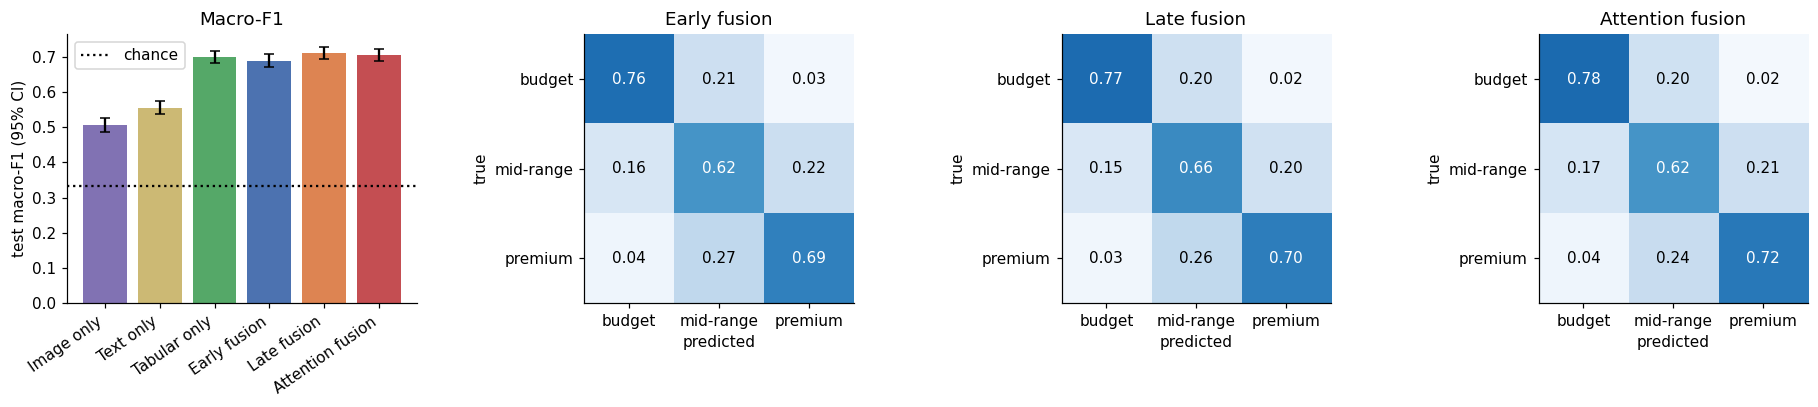

Figure 6. Test macro-F1 of unimodal and fusion models (left) and row-normalised confusion matrices of the three fusion solutions. Errors are almost all between adjacent tiers.
Table 12. Per-class test metrics.


precision  recall     f1  support
Early fusion     budget         0.764   0.760  0.762      732
                 mid-range      0.564   0.615  0.589      821
                 premium        0.750   0.690  0.719      877
Late fusion      budget         0.788   0.772  0.780      732
                 mid-range      0.585   0.655  0.618      821
                 premium        0.775   0.701  0.736      877
Attention fusion budget         0.761   0.777  0.769      732
                 mid-range      0.588   0.615  0.601      821
                 premium        0.768   0.721  0.744      877
Tabular only     budget         0.766   0.762  0.764      732
                 mid-range      0.579   0.631  0.604      821
                 premium        0.765   0.705  0.734      877

In [18]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
x = np.arange(len(ORDER))
ax[0].bar(x, main_tab["macro_f1"], yerr=[main_tab["macro_f1"] - main_tab["macro_f1_ci_low"], main_tab["macro_f1_ci_high"] - main_tab["macro_f1"]],
          color=[COLORS[n] for n in ORDER], capsize=3)
ax[0].axhline(1 / 3, ls=":", color="k", label="chance"); ax[0].set_xticks(x, ORDER, rotation=35, ha="right")
ax[0].set(ylabel="test macro-F1 (95% CI)", title="Macro-F1"); ax[0].legend()
for a, name in zip(ax[1:], fusion):
    cm = confusion_matrix(yt, TEST_P[name].argmax(1), normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3): a.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="w" if cm[i, j] > .5 else "k")
    a.set_xticks(range(3), mm.CLASSES); a.set_yticks(range(3), mm.CLASSES); a.set(xlabel="predicted", ylabel="true", title=name); a.grid(False)
finish_figure(fig, "Test macro-F1 of unimodal and fusion models (left) and row-normalised confusion matrices of the three "
              "fusion solutions. Errors are almost all between adjacent tiers.", "test_overview")

pc = pd.concat({n: mm.per_class(yt, TEST_P[n]) for n in fusion + [best_uni]})
show_table(pc, "Per-class test metrics.", "per_class", 3)

### 7.1 Overfitting assessment

In [19]:
of = pd.DataFrame({n: {"train_macro_f1": f1_score(y[IDX["train"]], TRAIN_P[n].argmax(1), average="macro"),
                       "val_macro_f1": f1_score(y[IDX["val"]], VAL_P[n].argmax(1), average="macro"),
                       "test_macro_f1": f1_score(yt, TEST_P[n].argmax(1), average="macro"),
                       "train_log_loss": log_loss(y[IDX["train"]], TRAIN_P[n]), "test_log_loss": log_loss(yt, TEST_P[n])} for n in ORDER}).T
of["train_test_gap"] = of["train_macro_f1"] - of["test_macro_f1"]
show_table(of, "Overfitting check: train vs validation vs test macro-F1. Late-fusion weights were fitted on validation, so "
           "its validation score is optimistic.", "overfitting", 3)
RESULTS["overfitting"] = of.to_dict("index")

Table 13. Overfitting check: train vs validation vs test macro-F1. Late-fusion weights were fitted on validation, so its validation score is optimistic.


,train_macro_f1,val_macro_f1,test_macro_f1,train_log_loss,test_log_loss,train_test_gap
Image only,0.759,0.504,0.507,0.728,0.975,0.253
Text only,0.982,0.560,0.556,0.315,0.913,0.426
Tabular only,0.763,0.706,0.701,0.559,0.672,0.062
Early fusion,0.806,0.696,0.690,0.493,0.670,0.117
Late fusion,0.833,0.704,0.711,0.451,0.662,0.122
Attention fusion,0.732,0.695,0.705,0.604,0.681,0.028


### 7.2 Encoder comparison and SOTA reference

In [20]:
enc_rows = {(MAIN, n): mm.metrics(yt, TEST_P[n]) for n in ["Early fusion", "Attention fusion"]}
for e, d_ in ENC_RESULTS.items():
    for n, P in d_.items():
        enc_rows[(e, n)] = mm.metrics(yt, P["test"])
enc_cmp = pd.DataFrame(enc_rows).T[["accuracy", "macro_f1", "roc_auc_ovr", "log_loss", "qwk"]]
enc_cmp["image probe (val)"] = [probe_tab.loc[f"{e} | image", "val_macro_f1"] for e in enc_cmp.index.get_level_values(0)]
enc_cmp["text probe (val)"] = [probe_tab.loc[f"{e} | text", "val_macro_f1"] for e in enc_cmp.index.get_level_values(0)]
show_table(enc_cmp, "Encoder comparison on the test split (same fusion hyperparameters).", "encoder_comparison", 3)
RESULTS["encoder_comparison"] = {f"{a} | {b}": v for (a, b), v in enc_cmp.to_dict("index").items()}

Table 14. Encoder comparison on the test split (same fusion hyperparameters).


accuracy  macro_f1  roc_auc_ovr  log_loss  \
EffNet-B0 + BERT Early fusion         0.686     0.690        0.864     0.670   
                 Attention fusion     0.702     0.705        0.865     0.681   
ViT-B/16 + SBERT Early fusion         0.701     0.705        0.864     0.671   
                 Attention fusion     0.696     0.700        0.861     0.693   
CLIP ViT-B/32    Early fusion         0.707     0.710        0.869     0.659   
                 Attention fusion     0.704     0.707        0.869     0.674   

                                     qwk  image probe (val)  text probe (val)  
EffNet-B0 + BERT Early fusion      0.701              0.461             0.560  
                 Attention fusion  0.721              0.461             0.560  
ViT-B/16 + SBERT Early fusion      0.718              0.502             0.578  
                 Attention fusion  0.709              0.502             0.578  
CLIP ViT-B/32    Early fusion      0.725              0.532             0.599  
                 Attention fusion  0.726              0.532             0.599

## 8. Modality contribution (Week 6) and robustness
* **Shuffle test** (early fusion): permute one modality block across test listings and measure the drop in macro-F1.
* **Masking test** (attention fusion): hide a modality at inference using the missing-modality mask.

In [21]:
rng = np.random.default_rng(0)
contrib = {}
base_e = f1_score(yt, TEST_P["Early fusion"].argmax(1), average="macro")
base_a = f1_score(yt, TEST_P["Attention fusion"].argmax(1), average="macro")
for j, m in enumerate(mm.MODALITIES):
    drops = []
    for _ in range(5):
        Bsh = {k: v.copy() for k, v in EB["test"].items()}
        perm = rng.permutation(len(yt)); Bsh[m] = Bsh[m][perm]
        pres = IMAGE_PRESENT[IDX["test"]][perm] if m == "image" else IMAGE_PRESENT[IDX["test"]]
        drops.append(base_e - f1_score(yt, early.predict_proba(Bsh, pres).argmax(1), average="macro"))
    row = {"early: shuffle drop": np.mean(drops)}
    if m != "tabular":
        pres = PRESENT[IDX["test"]].copy(); pres[:, j] = False
        Pm, _ = mm.attention_predict(att, FB["test"], pres)
        row["attention: masked drop"] = base_a - f1_score(yt, Pm.argmax(1), average="macro")
    row["attention: mean α"] = ALPHA["test"][PRESENT[IDX["test"]][:, j], j].mean()
    row["early: gain share"] = gain_share[m]
    contrib[m] = row
contrib = pd.DataFrame(contrib).T
show_table(contrib, "Modality contribution on the test split (macro-F1 drop when a modality is shuffled / masked).", "modality_contribution", 3)
RESULTS["modality_contribution"] = contrib.to_dict("index")

Table 15. Modality contribution on the test split (macro-F1 drop when a modality is shuffled / masked).


,early: shuffle drop,attention: masked drop,attention: mean α,early: gain share
image,-0.007,0.003,0.152,0.098
tabular,0.337,NaN,0.650,0.787
text,-0.001,0.002,0.204,0.115


## 9. Error analysis and uncertainty

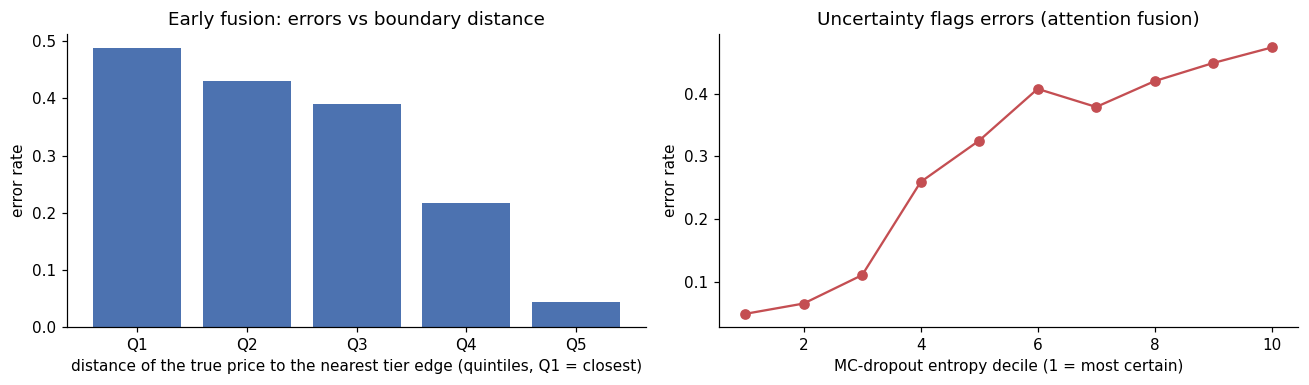

Figure 7. Left: most errors occur for listings priced close to a tier edge, i.e. discretisation of a continuous price is a main error source. Right: Monte-Carlo dropout entropy (Week 5) ranks listings by error risk (AUROC 0.71).
Table 16. Most confident errors of Early fusion (no photos or text shown, for privacy).


,true,pred,confidence,price_num,room_type,property_type,accommodates,bedrooms,neighbourhood_cleansed,number_of_reviews,image_used
1346,premium,budget,0.99,1098.50,Private room,Private room in home,1,1.0,Manningham,1,True
11008,mid-range,premium,0.98,282.04,Entire home/apt,Entire home,10,5.0,Wyndham,0,True
14118,mid-range,budget,0.97,221.00,Private room,Private room in home,2,0.0,Manningham,0,True
12727,mid-range,budget,0.97,289.00,Private room,Private room in home,2,1.0,Casey,0,True
11681,mid-range,budget,0.96,205.00,Private room,Private room in home,2,1.0,Port Phillip,43,True
2241,premium,budget,0.95,530.00,Private room,Private room in home,3,1.0,Melton,3,True
2993,premium,budget,0.95,435.97,Private room,Private room in home,1,1.0,Glen Eira,0,True
12931,mid-range,premium,0.94,311.50,Entire home/apt,Entire rental unit,6,3.0,Melbourne,6,True
12442,mid-range,budget,0.94,258.00,Private room,Private room in home,2,1.0,Casey,31,True
3080,mid-range,budget,0.94,248.00,Private room,Private room in home,2,1.0,Moonee Valley,0,True


In [22]:
best = best_fusion
pt = df["price_num"].values[IDX["test"]]
dist = np.min(np.abs(np.log(pt)[:, None] - np.log(edges)[None, :]), 1)       # log-distance to nearest tier edge
err = TEST_P[best].argmax(1) != yt
bins = pd.qcut(dist, 5, duplicates="drop")
eb = pd.DataFrame({"error": err, "bin": bins}).groupby("bin", observed=True)["error"].agg(["mean", "size"])
mean_p, entropy = mm.mc_dropout_predict(att, FB["test"], PRESENT[IDX["test"]])
att_err = mean_p.argmax(1) != yt
from sklearn.metrics import roc_auc_score
RESULTS["error_analysis"] = {"model": best, "error_rate": float(err.mean()),
                             "error_rate_nearest_quintile_to_edge": float(eb["mean"].iloc[0]),
                             "error_rate_farthest_quintile": float(eb["mean"].iloc[-1]),
                             "mc_dropout_entropy_auroc_for_errors": float(roc_auc_score(att_err, entropy))}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(range(len(eb)), eb["mean"], color=COLORS.get(best, "#4C72B0"))
ax[0].set_xticks(range(len(eb)), [f"Q{i+1}" for i in range(len(eb))])
ax[0].set(xlabel="distance of the true price to the nearest tier edge (quintiles, Q1 = closest)", ylabel="error rate", title=f"{best}: errors vs boundary distance")
q = np.quantile(entropy, np.linspace(0, 1, 11)); ib = np.clip(np.searchsorted(q, entropy, side="right") - 1, 0, 9)
ax[1].plot(range(1, 11), [att_err[ib == k].mean() for k in range(10)], marker="o", color=COLORS["Attention fusion"])
ax[1].set(xlabel="MC-dropout entropy decile (1 = most certain)", ylabel="error rate", title="Uncertainty flags errors (attention fusion)")
finish_figure(fig, "Left: most errors occur for listings priced close to a tier edge, i.e. discretisation of a continuous price "
              "is a main error source. Right: Monte-Carlo dropout entropy (Week 5) ranks listings by error risk "
              f"(AUROC {RESULTS['error_analysis']['mc_dropout_entropy_auroc_for_errors']:.2f}).", "error_analysis")

test_df = df.iloc[IDX["test"]].assign(true=[mm.CLASSES[k] for k in yt], pred=[mm.CLASSES[k] for k in TEST_P[best].argmax(1)],
                                      confidence=TEST_P[best].max(1), image_used=IMAGE_PRESENT[IDX["test"]])
worst = test_df[err].sort_values("confidence", ascending=False).head(12)
show_table(worst[["true", "pred", "confidence", "price_num", "room_type", "property_type", "accommodates", "bedrooms",
                  "neighbourhood_cleansed", "number_of_reviews", "image_used"]],
           f"Most confident errors of {best} (no photos or text shown, for privacy).", "confident_errors", 2)

## 10. Bias and fairness (Week 7)
Per-area accuracy, premium recall (equal opportunity) and predicted vs actual premium rate, with and without the area feature; plus subgroups that matter for the stakeholders (new listings without reviews, photos masked).

Table 17. Area disparity (areas with >= 30 test listings).


,groups,accuracy_min,accuracy_max,accuracy_gap,accuracy_sd,premium_recall_gap,overall_macro_f1
early fusion WITH area,19.0,0.543,0.844,0.301,0.089,0.556,0.690
early fusion WITHOUT area,19.0,0.543,0.828,0.285,0.084,0.468,0.681


Table 18. Subgroup macro-F1 on the test split.


,n,Tabular only macro-F1,Early fusion macro-F1,Late fusion macro-F1,Attention fusion macro-F1
no reviews yet,291.0,0.655,0.659,0.660,0.659
has reviews,2139.0,0.704,0.692,0.716,0.709
photo used,2342.0,0.701,0.690,0.712,0.706
photo missing / masked,88.0,0.699,0.681,0.699,0.658
room: Private room,508.0,0.478,0.415,0.476,0.498
room: Entire home/apt,1909.0,0.611,0.596,0.628,0.616


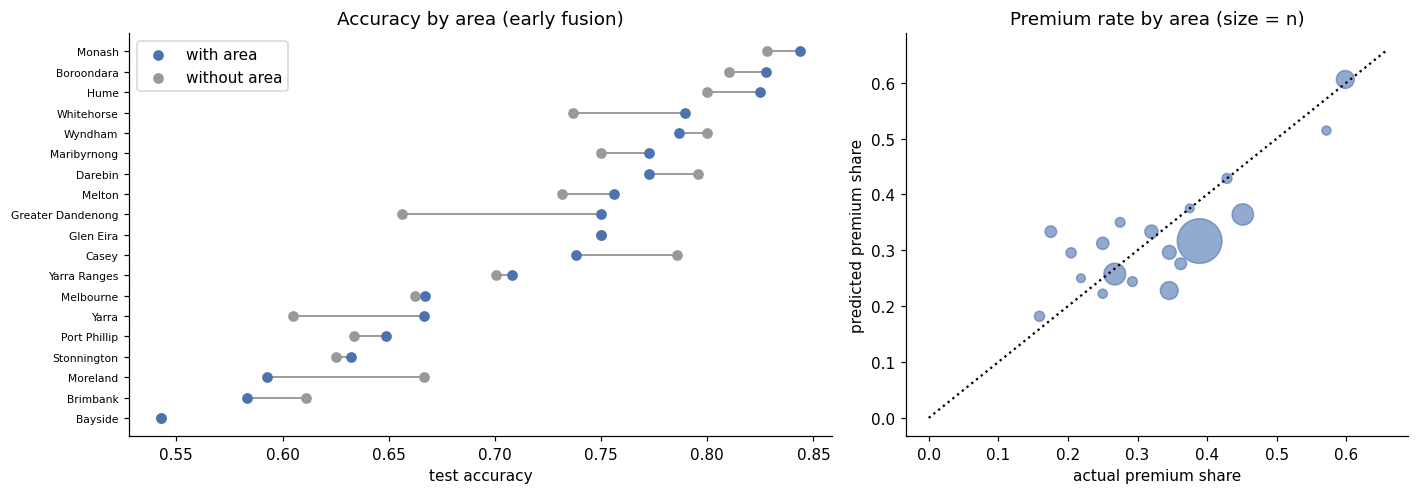

Figure 8. Per-area accuracy with vs without the area feature (left) and predicted vs actual premium share per area (right; points above the diagonal = areas the model over-labels premium).


In [23]:
TB_NA = make_blocks(MAIN, TAB_NOAREA, N_PCA_EARLY)
EB_NA = {s: sel(TB_NA["pca"], s) for s in IDX}
early_na = mm.EarlyFusionXGB(early_params, DEVICE).fit(EB_NA["train"], y[IDX["train"]], IMAGE_PRESENT[IDX["train"]])
P_na = early_na.predict_proba(EB_NA["test"], IMAGE_PRESENT[IDX["test"]])
area = df["neighbourhood_cleansed"].iloc[IDX["test"]]
gm_with = mm.group_metrics(yt, TEST_P["Early fusion"], area)
gm_without = mm.group_metrics(yt, P_na, area)
fair = pd.DataFrame({"early fusion WITH area": {**mm.disparity_summary(gm_with), "overall_macro_f1": f1_score(yt, TEST_P["Early fusion"].argmax(1), average="macro")},
                     "early fusion WITHOUT area": {**mm.disparity_summary(gm_without), "overall_macro_f1": f1_score(yt, P_na.argmax(1), average="macro")}}).T
show_table(fair, "Area disparity (areas with >= 30 test listings).", "fairness_area", 3)
RESULTS["fairness_area"] = fair.to_dict("index")

subg = {}
for lab, mask in [("no reviews yet", df["number_of_reviews"].iloc[IDX["test"]].values == 0),
                  ("has reviews", df["number_of_reviews"].iloc[IDX["test"]].values > 0),
                  ("photo used", IMAGE_PRESENT[IDX["test"]]), ("photo missing / masked", ~IMAGE_PRESENT[IDX["test"]])]:
    if mask.sum() >= 30:
        subg[lab] = {"n": int(mask.sum()), **{f"{n} macro-F1": f1_score(yt[mask], TEST_P[n][mask].argmax(1), average="macro") for n in ["Tabular only", "Early fusion", "Late fusion", "Attention fusion"]}}
for rt in df["room_type"].iloc[IDX["test"]].unique():
    msk = df["room_type"].iloc[IDX["test"]].values == rt
    if msk.sum() >= 30:
        subg[f"room: {rt}"] = {"n": int(msk.sum()), **{f"{n} macro-F1": f1_score(yt[msk], TEST_P[n][msk].argmax(1), average="macro", labels=[0, 1, 2], zero_division=0) for n in ["Tabular only", "Early fusion", "Late fusion", "Attention fusion"]}}
subg = pd.DataFrame(subg).T
show_table(subg, "Subgroup macro-F1 on the test split.", "subgroups", 3)
RESULTS["subgroups"] = subg.to_dict("index")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
gm = gm_with.join(gm_without[["accuracy"]], rsuffix="_noarea").sort_values("accuracy")
yy = np.arange(len(gm))
ax[0].hlines(yy, gm["accuracy"], gm["accuracy_noarea"], color="grey", lw=1)
ax[0].scatter(gm["accuracy"], yy, color=COLORS["Early fusion"], label="with area", zorder=4)
ax[0].scatter(gm["accuracy_noarea"], yy, color="#999999", label="without area", zorder=3)
ax[0].set_yticks(yy, gm.index, fontsize=7); ax[0].set(xlabel="test accuracy", title="Accuracy by area (early fusion)"); ax[0].legend()
ax[1].scatter(gm_with["actual_premium_rate"], gm_with["predicted_premium_rate"], s=gm_with["n"], alpha=.6, color=COLORS["Early fusion"])
lim = [0, max(gm_with[["actual_premium_rate", "predicted_premium_rate"]].max()) + .05]
ax[1].plot(lim, lim, ls=":", color="k"); ax[1].set(xlabel="actual premium share", ylabel="predicted premium share", title="Premium rate by area (size = n)")
finish_figure(fig, "Per-area accuracy with vs without the area feature (left) and predicted vs actual premium share per area "
              "(right; points above the diagonal = areas the model over-labels premium).", "fairness")

## 11. Efficiency (effectiveness vs cost)

In [24]:
eff = pd.DataFrame({n: {"test_macro_f1": main_tab.loc[n, "macro_f1"], "fit_s": COST[n]["fit_s"], "tuning_s": COST[n].get("tuning_s", np.nan),
                        "model_size_kb": COST[n]["size_kb"], "infer_ms_per_1000": COST[n]["infer_ms_per_1000"]} for n in ORDER}).T
show_table(eff, "Efficiency on a T4 GPU (feature extraction cost is shared by all models; see Table 'encoders').", "efficiency", 3)
RESULTS["efficiency"] = eff.to_dict("index")
RESULTS["cost_detail"] = COST
save_results()
print("Saved:", os.listdir(RES_DIR)[:5], "...", len(os.listdir(FIG_DIR)), "figures")

Table 19. Efficiency on a T4 GPU (feature extraction cost is shared by all models; see Table 'encoders').


,test_macro_f1,fit_s,tuning_s,model_size_kb,infer_ms_per_1000
Image only,0.507,1.780,67.055,1700.979,4.215
Text only,0.556,4.100,108.481,4403.800,5.026
Tabular only,0.701,1.162,48.165,1645.815,3.693
Early fusion,0.690,1.600,140.586,1993.623,8.812
Late fusion,0.711,7.041,223.702,7750.595,12.934
Attention fusion,0.705,9.766,71.171,1188.016,2.701


Saved: ['table01_split.csv', 'top_masked_names.json', 'table02_tabular_quality.csv', 'table03_encoders.csv', 'table04_linear_probe.csv'] ... 8 figures
